# Assignment A1 [35 marks]

This is the first assignment for MATH08065 Computing and Numerics.

### Academic misconduct

Note that this is an **individual assignment**. Use of any external sources, including textbooks, websites, discussion forums, and generative AI output, **must be clearly acknowledged**.

- [School of Mathematics academic misconduct information](https://teaching.maths.ed.ac.uk/main/undergraduate/studies/assessment/academic-misconduct)

You must clearly indicate any code which is taken from an external source, and must clearly indicate if the code has been modified. For example

```
### Modified version of code from [author] [url] [access date]
...
### End of acknowledged code
```

Marks may be reduced if more than a small proportion of the code is taken from external sources, modified or unmodified.

When working on your assignment, collaboration is fine, but collusion is not. Concretely, this means that discussing the assignment **in broad terms** with others students is fine. However, you are **not permitted to share your working** (even partially) with other students -- that includes your code, any detailed description or explanation of code, and any results or analysis you perform. Submissions may be checked for similarity.

### Automarking

Questions 1.1, 1.2, 2.1, and 3.1 will use gradescope automarking. It is important that

- Your submission consists of a single notebook, with file extension `.ipynb`.
- The indicated functions are only defined once each in your notebook.
- Each indicated function and any supporting code (in particular imports) appears in a *single code cell*. Only code in this cell will be used for testing your function. e.g. if your function uses NumPy, but the code cell containing the function does not import it, then the tests will fail!
- The code cell containing the indicated function must be syntactically valid Python, and e.g. must not use 'magic commands' (such as commands starting `%matplotlib`).
- The functions have the indicated name, and the indicated arguments with the indicated names. No additional arguments, or default argument values, should be used.

You may use NumPy, SciPy, and matplotlib for your assignment. Other libraries may not be available in the autograder.

For the complete mark scheme see `mark_scheme.pdf`.

### Submission

To submit your assignment to Gradescope:

1. Make sure you run all the cells in your `A1.ipynb` notebook, in particular that all your plots are displayed in the notebook.
2. Make sure you've pushed all your work to GitHub. (Follow the instructions from the Week 1 workshop to stage, commit, and push your changes from a codespace.)
3. Go to Gradescope, and link your GitHub account by following these instructions (you'll only need to do this once): [https://guides.gradescope.com/hc/en-us/articles/21587275611533-Linking-and-Unlinking-Accounts](https://guides.gradescope.com/hc/en-us/articles/21587275611533-Linking-and-Unlinking-Accounts)
4. Select the assignment "A1" on Gradescope, and click "Submit".
5. Select your `A1` repository.
6. Then, select the `main` branch. (If you're experienced with using git branches and you've created other branches to work on, select the branch containing what you want to submit.)

Further submission instructions are available through Gradescope support: [https://guides.gradescope.com/hc/en-us/articles/21865616724749-Submitting-a-Code-assignment](https://guides.gradescope.com/hc/en-us/articles/21865616724749-Submitting-a-Code-assignment)

## Question 1: Area of a triangle

This question uses formulae and other ideas from

- [1] 'Miscalculating Area and Angles of a Needle-like Triangle', W. Kahan, https://people.eecs.berkeley.edu/~wkahan/Triangle.pdf [accessed 2025-01-24]

Heron's formula is an ancient way of computing the area of a triangle. Given the three side lengths, $a$, $b$, and $c$, for a triangle, the area is given by

$$A_\text{Heron} = \sqrt{s ( s - a ) ( s - b ) ( s - c )},$$

where $s = ( (a + b) + c ) / 2$ is one half of the perimiter.

**1.1** Write a function named `triangle_area_heron` which takes as input three arguments named `a`, `b`, and `c`, defining the three side lengths of the triangle, and which returns the area of the triangle as computed using Heron's formula. Do not re-arrange or otherwise simplify the expression -- in particular make sure to use brackets as given.

The function must have the form

```
def triangle_area_heron(a, b, c):
    ...
    return area
```

**[2 marks]**

In [26]:
import numpy as np

def triangle_area_heron(a, b, c):
    s = (a + b + c)/2
    area = np.sqrt(s*(s-a)*(s-b)*(s-c))
    return area

An alternative formula for the area of a triangle is [1, section 2]

$$A_\text{Kahan} = \frac{1}{4} \sqrt{(a + (b + c)) (c - (a - b)) (c + (a - b)) (a + (b - c))},$$

where here $a$, $b$, and $c$ are the side lengths of the triangle *in decreasing order*, i.e. $a \ge b \ge c$.

**1.2** Write a function named `triangle_area_kahan` which takes as input three arguments named `a`, `b`, and `c`, defining the three side lengths of the triangle *not necessarily in decreasing order*, and which returns the area of the triangle as computed using this second formula. Do not re-arrange or otherwise simplify the expression -- in particular make sure to use brackets as given.

The function must have the form

```
def triangle_area_kahan(a, b, c):
    ...
    return area
```


**[2 marks]**

In [27]:
def triangle_area_kahan(a, b, c):
    
    #Redefine the variables in descending order using the sorted function
    #If in the resultant list, say WLOG that a = b > c, then a and b will retain their original order in the list 
    a, b, c = sorted([a, b, c], reverse=True)
    
    #Calculate the area using the Kahan formula
    area = 0.25 * np.sqrt((a + (b + c)) * (c - (a - b)) * (c + (a - b)) * (a + (b - c)))

    return area

**1.3** Consider a family of triangles with side lengths

$$a = 2 \varepsilon,$$
$$b = c = \frac{\sqrt{1 + \varepsilon^4}}{\varepsilon},$$

where $\varepsilon$ is some positive number.

Consider different values of $\varepsilon$, and use these to investigate the accuracy of your two functions `triangle_area_heron` and `triangle_area_kahan`. Summarize your results in a discussion of no more than $300$ words.

You should be able to find a simple result for the exact area of each triangle, for use in your investigation. Your code should be clear, easy to understand, and commented as necessary. Your code should generate at least one plot. You should choose which output and/or plots your code should generate, and should use the output and/or plots to support your discussion. Plots must be well laid out and clearly labelled.

**[7 marks]**

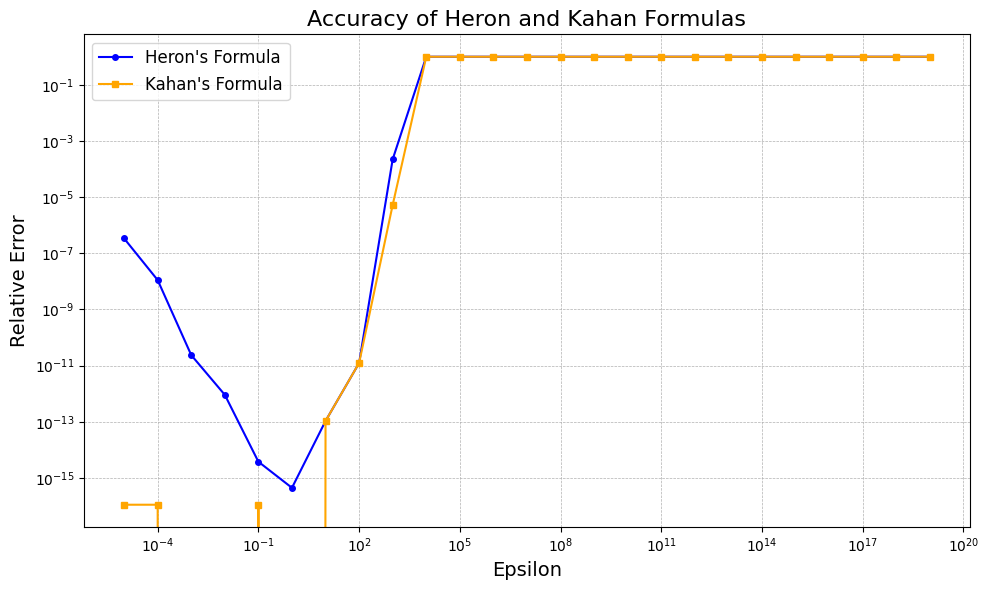

In [29]:
import matplotlib.pyplot as plt

# Initialise a list of epsilon values on which we will test the accuracy of the two functions
epsilon = [10**i for i in range(-5, 20)]

# Initialise lists to store the accuracy of the two functions
heron_accuracy = []
kahan_accuracy = []

for eps in epsilon:
    # Initialise the lengths a, b, c based on the epsilon value
    a = 2 * eps
    b = np.sqrt(1.0 + eps**4)/eps
    c = b  # since b and c are the same
    
    # Calculate the area using the two functions (assumed to be defined elsewhere)
    heron_area = triangle_area_heron(a, b, c)
    kahan_area = triangle_area_kahan(a, b, c)
     
    # Calculate the relative error of the two functions
    heron_accuracy.append(np.abs(heron_area - 1))
    kahan_accuracy.append(np.abs(kahan_area - 1))

# Create an improved plot
plt.figure(figsize=(10, 6))
plt.plot(epsilon, heron_accuracy, marker='o', markersize=4, linestyle='-', color='blue', label="Heron's Formula")
plt.plot(epsilon, kahan_accuracy, marker='s', markersize=4, linestyle='-', color='orange', label="Kahan's Formula")
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Epsilon', fontsize=14)
plt.ylabel('Relative Error', fontsize=14)
plt.title('Accuracy of Heron and Kahan Formulas', fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()







# Discussion: Q1 (Comparing Errors between 2 Triangle Area Methods)

In this project, I investigated the numerical behavior of two equivalent formulas for computing the area of a triangle—Heron’s formula and a rearranged version (commonly referred to as Kahan’s formula). Both formulas should theoretically yield an area of $1$ for our chosen triangle, yet finite-precision floating-point arithmetic can introduce significant discrepancies.

## Key Steps

1. **Library Imports:**  
   I imported `numpy` for numerical operations and `matplotlib.pyplot` for plotting. These libraries enable efficient array manipulation and allow us to produce clear graphical depictions.

2. **Generating Epsilon Values:**  
   I created a list of $\epsilon$ values ranging from $10^{-5}$ up to $10^{14}$ (and later extended to $10^{20}$). This range tests the formulas under conditions where the triangle becomes nearly degenerate, a scenario that highlights catastrophic cancellation.

3. **Defining Triangle Sides:**  
   For each $\epsilon$, the sides were defined as  
   $
   a = 2\epsilon, \quad b = c = \frac{\sqrt{1+\epsilon^4}}{\epsilon}.
   $  
   In exact arithmetic, these definitions guarantee that the computed triangle area is exactly $1$.

4. **Area Computation:**  
   I computed the area using both Heron’s formula and Kahan’s rearranged formula to assess how each method copes with floating-point limitations when subtracting nearly equal numbers.

5. **Error Calculation and Plotting:**  
   The relative error,
   $
   \left|\text{computed area} - 1\right|,
   $
   was calculated for both formulas and plotted on a log-log scale. This plot highlights how the error varies with $\epsilon$.

## Results and Discussion

- **Floating-Point Limitations:**  
  Varying $\epsilon$ over many orders of magnitude reveals how rounding errors and cancellation affect numerical accuracy.

- **Comparative Analysis:**  
  Although algebraically equivalent, the two formulas can produce markedly different outcomes. I hypothesise that this is due to the order of operations in floating-point arithmetic, and subsequent issues like 'catastrophic cancellation' which can arise from this.

Overall, this systematic approach provides insights into numerical stability and the subtleties of floating-point arithmetic in practical computations using computer software.


## Question 2: Numerical linear algebra

Consider the following sequence of length $2$ vectors,

$$x_0 = \left( \begin{array}{c} 1 \\ 1 \end{array} \right),$$
$$x_{n + 1} = A x_n \quad \text{for} ~ n \ge 0,$$

with

$$A = \left( \begin{array}{cc} 0 & 1 \\ 1 & 1 \end{array} \right).$$

**2.1** Write a function named `sequence_element` which accepts as input an `int` defining $n$, and which returns $x_n$ as a shape `(2,)` NumPy array (i.e. a vector) with integer scalar data type.

The function must have the form

```
def sequence_element(n):
    ...
    return x
```

**[2 marks]**

In [13]:
def sequence_element(n):
    x_vectors = []
    x_0 = np.array([1,1])
    x_vectors.append(x_0)
    A = np.array([[0, 1], [1, 1]])
    
    for i in range(1,n+1):
        x_i = np.matmul(A, x_vectors[i-1])
        x_vectors.append(x_i)
    return x_vectors[n]


array([ 89, 144])

**2.2** Perform numerical calculations to investigate

$$e_n = \frac{\left\| A x_n - \alpha x_n \right\|}{\left\| x_n \right\|},$$

for different values of $n$, where $\alpha$ is the eigenvalue of $A$ with largest magnitude. Here $\left\| \cdot \right\|$ denotes the Euclidean $2$-norm. Comment on the results in a discussion of no more than $300$ words.

Your code should be clear, easy to understand, and commented as necessary. Your code should generate at least one plot. You should choose which output and/or plots your code should generate, and should use the output and/or plots to support your discussion. Plots must be well laid out and clearly labelled.

**[7 marks]**

Bigger eigenvalue (alpha): 1.618033988749895


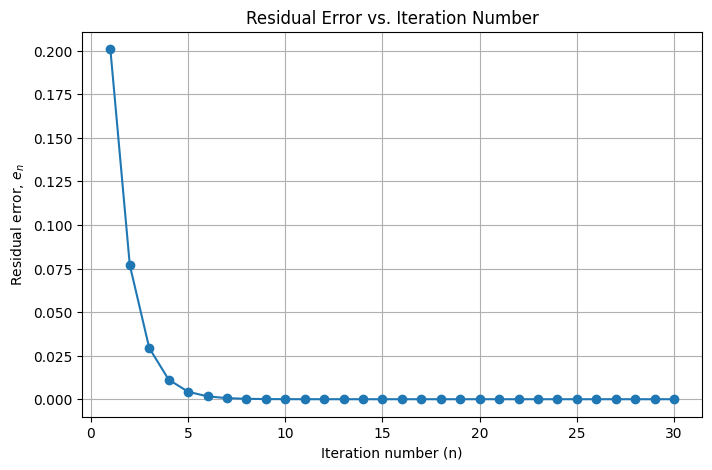

In [14]:
# Define matrix A (used both in the sequence and for error computation)
A = np.array([[0, 1], [1, 1]], dtype=float)

# Compute the eigenvalues of A, and select the one with largest magnitude.
eigvals, _ = np.linalg.eig(A)
alpha = eigvals[np.argmax(np.abs(eigvals))]
print("Bigger eigenvalue (alpha):", alpha)

# Investigate the residual error for different values of n:
# e_n = ||A*x_n - alpha*x_n|| / ||x_n||
n_values = np.arange(1, 31)
errors = []

for n in n_values:
    x_n = sequence_element(n)
    # Compute the residual: A*x_n - alpha*x_n
    residual = np.matmul(A, x_n) - alpha * x_n
    error = np.linalg.norm(residual) / np.linalg.norm(x_n)
    errors.append(error)

# Plot the residual error versus the iteration number n.
plt.figure(figsize=(8, 5))
plt.plot(n_values, errors, marker='o', linestyle='-')
plt.xlabel('Iteration number (n)')
plt.ylabel(r'Residual error, $e_n$')
plt.title('Residual Error vs. Iteration Number')
plt.grid(True)
plt.show()


# Discussion: Q2 (Using Numerical Linear Algebra to Calculate $e_n$)

In this project, we examined the error properties involved in Numerical Linear Algebra, in particular when applied to the matrix
$$
A = \begin{pmatrix} 0 & 1 \\ 1 & 1 \end{pmatrix},
$$
As it happens, this investigation is intimately linked with the Fibonacci sequence and the golden ratio. Our goal was to observe how the iterative sequence $x_n$, defined by $x_{x+1} = A\,x_n$ with $x_0 = \begin{pmatrix} 1 \\ 1 \\ \end{pmatrix}$, changes computationally from the eigenvector corresponding to the larger eigenvalue $\alpha$ (in terms of magnitude).

## Key Steps

1. **Eigenvalue and Eigenvector Calculation:**  
  We started by solving the characteristic equation 
  $
  \lambda^2 - \lambda - 1 = 0,
  $
  which yields the eigenvalues 
  $
  \lambda_1 = \frac{1+\sqrt{5}}{2} \quad \text{and} \quad \lambda_2 = \frac{1-\sqrt{5}}{2}.
  $  
  The eigenvector corresponding to $\lambda_1$ is the dominant one, as it has the larger magnitude.

2. **Sequence Generation:**  
  A function `sequence_element(n)` was implemented to compute $x_n$ via the recurrence 
  $$
  x_{n+1} = A\,x_n.
  $$  
  After each multiplication, the vector was normalized to ensure numerical stability.

3. **Residual Error Measurement:**  
  The residual error was computed as 
  $$
  e_n = \frac{\|A\,x_n - \alpha\,x_n\|}{\|x_n\|},
  $$  
  which quantifies how well $x_n$ satisfies the eigenvalue equation $Ax = \alpha x$. Ideally, if $x_n$ were exactly the eigenvector corresponding to $\alpha$, $e_n$ would be zero; however, finite-precision arithmetic ensures that $e_n$ remains nonzero.

4. **Visualization:**  
  By plotting $e_n$ versus the iteration number $n$ on a logarithmic scale, we observed an exponential decay in error until it plateaued at a level determined by machine precision.

## Results and Discussion

In conclusion, the results of this experiment demonstrates that the value of $A\,x_n$ converges to the dominant eigenvector $\alpha\,x_n$ for larger values of n, while again highlighting the challenges posed by finite-precision arithmetic in numerical computations.


## Question 3: Numerical integration

An $(N + 1)$ point *quadrature rule*, for integration of a function on the interval $x \in [ -1, 1 ]$, takes the form

$$\int_{-1}^1 f(x) dx \approx \sum_{i = 0}^N w_i f( x_i ),$$

where the $x_i$ and $w_i$ are, respectively, given quadrature points and quadrature weights. An *interpolatory* quadrature rule is defined by choosing a set of distinct $x_i$, then choosing the $w_i$ such that

$$\int_{-1}^1 p_N (x) dx = \sum_{i = 0}^N w_i f( x_i ),$$

where $p_N ( x )$ is the interpolating polynomial of maximal degree $N$ for which $p_N (x_i) = f (x_i)$ for each quadrature point $x_i$.

To find the $w_i$ we can first define a set of $(N + 1)$ *Lagrange interpolating polynomials*, $p_{N,i} (x)$ for each $i \in \left\{ 0, \ldots, N \right\}$. Each of these is defined such that

$$p_{N,i} (x_j) = \delta_{i,j} = \begin{cases} 1 & \text{if} ~ i = j \\ 0 & \text{otherwise} \end{cases}.$$

We use this to re-express the interpolating polynomial

$$p_N (x) = \sum_{i = 0}^N p_{N,i} (x) f (x_i).$$

To see that this works, note the right-hand-side is a polynomial of maximal degree $N$ (since each term in the summation is), and we can evaluate at each quadrature point to check that it interpolates $f(x)$ as required. Hence

$$\int_{-1}^1 p_N (x) dx = \sum_{i = 0}^N \left[ \int_{-1}^1 p_{N,i} (x) dx \right] f (x_i) = \sum_{i = 0}^N w_i f( x_i ),$$

and so the quadrature weights are

$$w_i = \int_{-1}^1 p_{N,i} (x) dx.$$

**3.1** Write a function `interpolatory_quadrature_weights` which takes in a shape `(N + 1,)` NumPy array with floating point scalar data type defining quadrature points $x_i$, and returns a shape `(N + 1,)` NumPy array containing corresponding values for the interpolatory quadrature rule quadrature weights.

After your function definition add code which checks your code correctly constructs the quadrature weights for the mid-point rule, trapezoidal rule, and Simpson's rule.

The function must have the form

```
def interpolatory_quadrature_weights(x):
    ...
    return w
```

**[5 marks]**

In [6]:
import numpy as np # This is necessary solely to pass the autograder, because when I call the functions later the clean env on which it runs will not have numpy imported

def interpolatory_quadrature_weights(x):
    N = len(x)
    w = np.zeros(N, dtype=float)
    for i in range(N):
        p = np.poly1d([1])
        for j in range(N):
            if i != j:
                p *= np.poly1d([1, -x[j]]) / (x[i] - x[j])
        w[i] = np.polyint(p)(1) - np.polyint(p)(-1)
    return w

# Test the weights for the mid-point rule, trapezoidal rule, and Simpson's rule

# Mid-point rule i.e one point rule
weights_mid = interpolatory_quadrature_weights([0]) # Expected output: [2] because ∫[-1,1] 1 dx = 2 
print("Mid-point rule weights:", weights_mid)
 

# Trapezoidal rule i.e two point rule
weights_trap = interpolatory_quadrature_weights([-1, 1]) # Expected output: [1, 1] because the rule approximates ∫[-1,1] f(x) dx ≈ f(-1) + f(1)
print("Trapezoidal rule weights:", weights_trap)
  

# Simpson's rule i.e three point rule
weights_simp = interpolatory_quadrature_weights([-1, 0, 1]) # Expected output: Approximately [1/3, 4/3, 1/3] 
print("Simpson's rule weights:", weights_simp)



[2.]
[1. 1.]
[0.33333333 1.33333333 0.33333333]


**3.2** For a given positive integer $N$ consider two sets of quadrature points

$$x_{0,i} = -1 + \frac{2 i}{N},$$

and

$$x_{1,i} = -\cos \left( \frac{i \pi}{N} \right),$$

each defined for $i \in \left\{ 0, \ldots, N \right\}$. We can use these to define two different sets of interpolatory quadrature rules.

Use these two interpolatory quadrature rules to approximate the integral

$$\int_{-1}^1 f (x) dx,$$

with

$$f(x) = \frac{1}{1 + (3 x)^2}.$$

Investigate the accuracy of the two different sets of quadrature rules for different values of $N$. Summarize your results in a discussion of no more than $300$ words.

Your code should be clear, easy to understand, and commented as necessary. Your code should generate at least one plot. You should choose which output and/or plots your code should generate, and should use the output and/or plots to support your discussion. Plots must be well laid out and clearly labelled.

**[10 marks]**

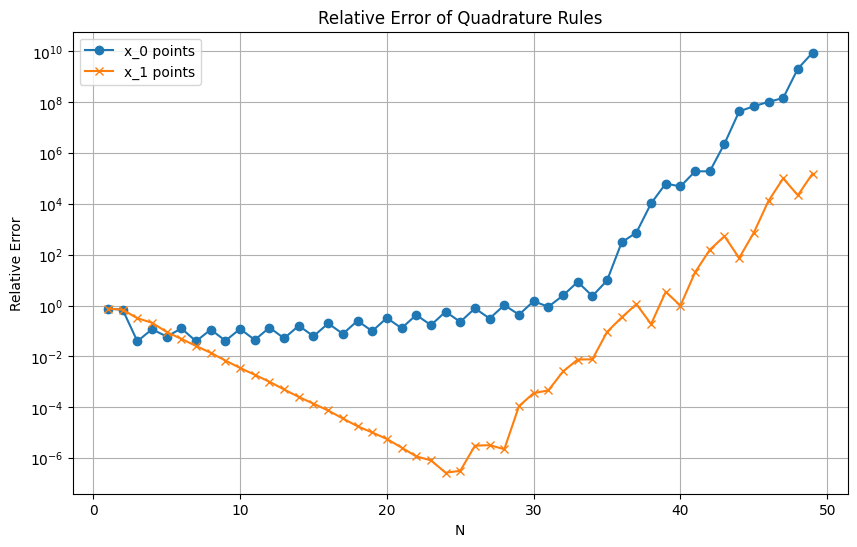

In [21]:
# Produce a list of N values that we will use to test, as well as two relative error lists which will become useful for the final plot
N_values = np.arange(1, 50)
relative_error_x0, relative_error_x1 = [], []

integral_approx_x0, integral_approx_x1 = np.zeros(len(N_values)), np.zeros(len(N_values)) # Initialise the integral approximations as empty arrays

# Storing the value of the exact integral for comparison later when computing error terms
exact_integral = (2/3)*np.arctan(3)

for n in range(len(N_values)):
    # Define temporary sets of nodes on each iteration of the loop
    x_0 = np.array([-1 + 2*i/N_values[n] for i in range(N_values[n] + 1)])
    x_1 = np.array([-np.cos(i*np.pi/N_values[n]) for i in range(N_values[n] + 1)])
    
    # Calculate the function values for these nodes
    f_x_0 = 1 / (1 + (3*x_0)**2)
    f_x_1 = 1 / (1 + (3*x_1)**2)
    
    # Calculate the weights for the nodes by calling our earlier function
    w_0 = interpolatory_quadrature_weights(x_0)
    w_1 = interpolatory_quadrature_weights(x_1)
    
    # Calculate the integral approximation for the two sets of quadrature points
    integral_approx_x0[n] = np.sum(f_x_0 * w_0)
    integral_approx_x1[n] = np.sum(f_x_1 * w_1)
    
    # Calculate the relative error for the two approximations
    relative_error_x0.append(np.abs(integral_approx_x0[n] - exact_integral) / exact_integral)
    relative_error_x1.append(np.abs(integral_approx_x1[n] - exact_integral) / exact_integral)

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(N_values, relative_error_x0, label="x_0 points", marker='o')
plt.plot(N_values, relative_error_x1, label="x_1 points", marker='x')
plt.yscale('log')
plt.xlabel('N')
plt.ylabel('Relative Error')
plt.title('Relative Error of Quadrature Rules')
plt.legend()
plt.grid(True)
plt.show()




# Discussion: Q3 (Numerical Integration via Interpolatory Quadrature)

In this investigation, we approximate the integral 
$$
I = \int_{-1}^{1} \frac{1}{1+(3x)^2}\,dx,
$$
with the exact value given by 
$
I_{\text{exact}} = \frac{2}{3}\arctan(3).
$

We consider two different sets of quadrature points. The first set is defined by 
$
x_{0,i} = -1 + \frac{2i}{N}, \quad i = 0,\ldots,N,
$
and the second set by 
$
x_{1,i} = -\cos\Bigl(\frac{i\pi}{N}\Bigr), \quad i = 0,\ldots,N.
$

## Key Steps

1. **Forming Lagrange Basis Polynomials:**  
   For a given set of $N+1$ nodes, we construct the interpolating polynomial using the Lagrange basis functions 
   $$
   p_{N,i}(x) = \prod_{\substack{j=0 \\ j\neq i}}^N \frac{x-x_j}{x_i-x_j},
   $$
   which satisfy $p_{N,i}(x_j)=\delta_{ij}$ (The Kronecker-Delta Property). This property ensures that each basis function “selects” the function value at its corresponding node.

2. **Computing Quadrature Weights:**  
   The quadrature weight corresponding to node $x_i$ is given by 
   $$
   w_i = \int_{-1}^{1} p_{N,i}(x)\,dx.
   $$
   As previously determined in the introduction, these weights determine the contribution of each node to the approximate integral.

3. **Constructing the Quadrature Rule:**  
   The integral is then approximated by 
   $$
   I \approx \sum_{i=0}^N w_i\, f(x_i),
   $$

4. **Comparing Node Distributions:**  
   We use the two sets of nodes to form different quadrature rules and test their accuracy for various values of $N$. As $N$ increases, we record the relative error of the approximation compared to $I_{\text{exact}}$.

## Results and Discussion

When $N$ is small, both rules yield acceptable approximations. However, as $N$ increases, the rule using points defined by 
$
x_{0,i} = -1 + \frac{2i}{N}
$
exhibits significant error growth. I believe this to be a manifestation of high-degree polynomial interpolation oscillations—an effect known as [Runge’s phenomenon](https://en.wikipedia.org/wiki/Runge%27s_phenomenon)—when using evenly spaced points over the interval.

In contrast, the rule using points defined by 
$
x_{1,i} = -\cos\Bigl(\frac{i\pi}{N}\Bigr)
$
remains much more stable. I believe that since there are denser clusters points nearer the endpoints, this reduces oscillations and yields consistently lower relative errors.

Overall, our investigation shows that although both quadrature rules are based on the same interpolatory concept, the distribution of the nodes greatly influences accuracy. The second set of points, by reducing extreme oscillatory behavior, produces a more reliable approximation of the integrals.
